# 基于机器学习的交易策略

本 Notebook 根据《Python 算法交易》中 “ML-Based Trading Strategy” 一节整理，使用天勤 TqSdk 获取螺纹钢主力连续合约数据，研究如何将机器学习的方向预测转化为交易策略。

学习顺序沿用原书本节的四个部分：向量化回测 → 最优杠杆 → 风险分析 → 保存模型对象。先判断预测信号扣费后能否盈利，再分析仓位大小如何影响资金曲线，最后考察回撤与 VaR。

本例为历史数据上的教学实验，不构成投资建议。


同时保存训练时的标的、K 线周期、滚动窗口、滞后阶数、基础特征及输入列顺序。在线预测和离线核对均从这份训练配置读取参数，避免重复手写配置导致偏差；另保存原测试期起点，便于选取相同的验证时段。

## 1. 向量化回测

### 1.1. 数据准备

本例使用螺纹钢主力连续合约 `KQ.m@SHFE.rb` 的 10 分钟 K 线，固定样本为 **2025-11-10 21:00 至 2026-10-26 14:40，共 8,000 根**。

这份数据此前通过天勤近期行情接口取得，已保存为 `KQ_m_SHFE_rb_600s_8000_20261026.csv`。下面直接读取这份快照，不再重新请求“最近 8,000 根”，以保证重复运行时训练集、测试集和图中的日期范围保持一致。CSV 时间为上海本地时间，包含开、高、低、收和成交量等字段。天勤账户配置、连接及取数代码均已注释，仅留作参考；日常运行只读 CSV，不需要安装天勤 SDK 或配置天勤账户。

交易成本在生成策略仓位后统一处理。本例以成交金额的万分之一（0.1‰）作为比例成本参数，具体计费假设见第 1.4 节。与只观察收益的基础回测相比，本例还会进一步分析杠杆和风险。


In [1]:
from pathlib import Path
import pandas as pd

In [2]:
instrument = "KQ.m@SHFE.rb"
bar_seconds = 600
n_bars = 8_000

# 固定读取此前保存的行情快照，避免每次运行改变样本区间。
csv_path = Path("KQ_m_SHFE_rb_600s_8000_20261026.csv")
raw = pd.read_csv(csv_path, index_col="datetime", parse_dates=True)
print(f"共 {len(raw)} 根 K 线：{raw.index.min()} 至 {raw.index.max()}")
raw.tail()

共 8000 根 K 线：2025-11-10 21:00:00 至 2026-10-26 14:40:00


,open,high,low,close,volume,complete
datetime,,,,,,
2026-10-26 14:00:00,3038.0,3040.0,3036.0,3037.0,11718,True
2026-10-26 14:10:00,3037.0,3039.0,3035.0,3038.0,10454,True
2026-10-26 14:20:00,3038.0,3039.0,3035.0,3038.0,6018,True
2026-10-26 14:30:00,3038.0,3039.0,3034.0,3039.0,9018,True
2026-10-26 14:40:00,3039.0,3040.0,3037.0,3038.0,7686,True


In [3]:
raw.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 8000 entries, 2025-11-10 21:00:00 to 2026-10-26 14:40:00
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   open      8000 non-null   float64
 1   high      8000 non-null   float64
 2   low       8000 non-null   float64
 3   close     8000 non-null   float64
 4   volume    8000 non-null   int64  
 5   complete  8000 non-null   bool   
dtypes: bool(1), float64(4), int64(1)
memory usage: 382.8 KB


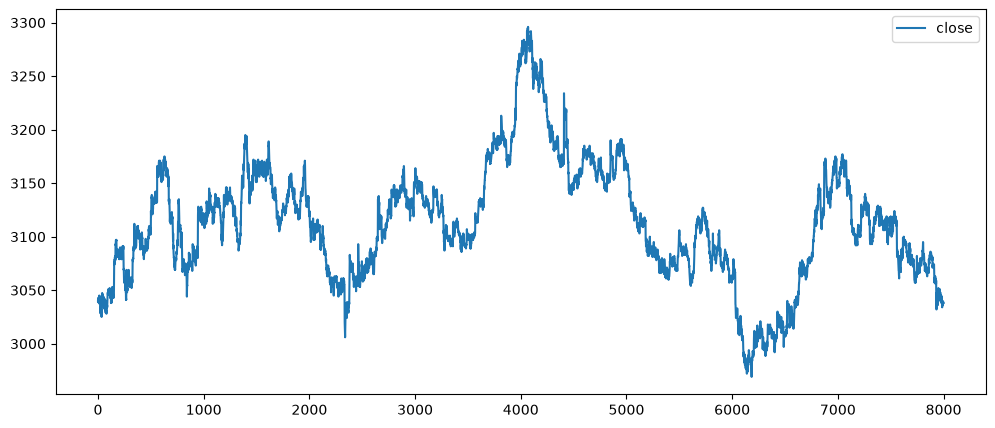

In [4]:
# 先绘制收盘价，观察这段样本的整体走势。
# 横轴使用 K 线序号，避免休市空档占据图中的时间宽度；后续收益图也采用这一方式。
raw['close'].reset_index(drop=True).plot(figsize=(12, 5), legend=True);

### 1.2. 构造特征与预测目标

模型的任务是根据已经发生的行情，预测下一段价格变动的方向。为此，先从收盘价构造收益、波动率、动量和价格水平等特征，再将特征滞后，使每一行的输入只包含此前已经可见的信息。

下面先用 20 根 K 线作为滚动窗口计算基础特征。滚动计算产生的缺失值需要先删除，才能继续构造训练样本。


In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

data = pd.DataFrame(raw['close'])
data.columns = [instrument,]

window = 20
data['return'] = np.log(data / data.shift(1))
data['volatility'] = data['return'].rolling(window).std()
momentum_tol = 1e-12  # 数值容差，不是交易信号阈值
mean_return = data['return'].rolling(window).mean()
data['momentum'] = np.sign(mean_return.mask(mean_return.abs() <= momentum_tol, 0.0))
data['sma'] = data[instrument].rolling(window).mean()
data['min'] = data[instrument].rolling(window).min()
data['max'] = data[instrument].rolling(window).max()

data.dropna(inplace=True)
data

,KQ.m@SHFE.rb,return,volatility,momentum,sma,min,max
datetime,,,,,,,
2025-11-11 10:30:00,3036.0,-0.002632,0.001016,-1.0,3040.60,3036.0,3045.0
2025-11-11 10:40:00,3031.0,-0.001648,0.001075,-1.0,3040.15,3031.0,3045.0
2025-11-11 10:50:00,3029.0,-0.000660,0.001081,-1.0,3039.65,3029.0,3045.0
2025-11-11 11:00:00,3030.0,0.000330,0.001070,-1.0,3039.10,3029.0,3045.0
2025-11-11 11:10:00,3034.0,0.001319,0.001107,-1.0,3038.65,3029.0,3045.0
...,...,...,...,...,...,...,...
2026-10-26 14:00:00,3037.0,-0.000329,0.000949,-1.0,3039.35,3034.0,3045.0
2026-10-26 14:10:00,3038.0,0.000329,0.000954,-1.0,3039.10,3034.0,3045.0
2026-10-26 14:20:00,3038.0,0.000000,0.000952,-1.0,3038.90,3034.0,3045.0


各基础特征的含义如下：

- `return`：相邻收盘价的对数收益率。
- `volatility`：过去 20 根 K 线对数收益率的标准差，用于衡量波动程度。`volatility` 表示波动率，与成交量 `volume` 区分。
- `momentum`：过去 20 根 K 线平均对数收益率的符号，表示近期动量方向。
- `sma`：过去 20 根 K 线收盘价的简单移动平均。
- `min` / `max`：过去 20 根 K 线收盘价的最低值与最高值。

接着对这 6 类特征分别取第 1 至第 6 阶滞后，共得到 36 个模型输入列，名称保存在 `cols` 中。例如，第 $t$ 行的 `return_lag_1` 是第 $t-1$ 根 K 线的收益，`return_lag_6` 是第 $t-6$ 根 K 线的收益。模型使用这些历史特征预测第 $t$ 根 K 线的收益方向。


In [6]:
lags = 6
features = ['return', 'volatility', 'momentum', 'sma', 'min', 'max']
cols = []

for f in features:
    for lag in range(1, lags + 1):
        col = f'{f}_lag_{lag}'
        data[col] = data[f].shift(lag)
        cols.append(col)

data.dropna(inplace=True)
# 标签：本根 K 线对数收益 >= 0 为 +1，<0 为 -1
data['direction'] = np.where(data['return'] >= 0, 1, -1)

In [7]:
# direction：收益 >= 0 为 +1，否则 -1
data[cols].head(lags)

,return_lag_1,return_lag_2,return_lag_3,return_lag_4,return_lag_5,return_lag_6,volatility_lag_1,volatility_lag_2,volatility_lag_3,volatility_lag_4,...,min_lag_3,min_lag_4,min_lag_5,min_lag_6,max_lag_1,max_lag_2,max_lag_3,max_lag_4,max_lag_5,max_lag_6
datetime,,,,,,,,,,,,,,,,,,,,,
2025-11-11 13:30:00,-0.00033,0.001319,0.000330,-0.000660,-0.001648,-0.002632,0.001090,0.001107,0.001070,0.001081,...,3029.0,3029.0,3031.0,3036.0,3045.0,3045.0,3045.0,3045.0,3045.0,3045.0
2025-11-11 13:40:00,-0.00165,-0.000330,0.001319,0.000330,-0.000660,-0.001648,0.001137,0.001090,0.001107,0.001070,...,3029.0,3029.0,3029.0,3031.0,3045.0,3045.0,3045.0,3045.0,3045.0,3045.0
2025-11-11 13:50:00,0.00099,-0.001650,-0.000330,0.001319,0.000330,-0.000660,0.001167,0.001137,0.001090,0.001107,...,3029.0,3029.0,3029.0,3029.0,3045.0,3045.0,3045.0,3045.0,3045.0,3045.0
2025-11-11 14:00:00,0.00033,0.000990,-0.001650,-0.000330,0.001319,0.000330,0.001166,0.001167,0.001137,0.001090,...,3028.0,3029.0,3029.0,3029.0,3045.0,3045.0,3045.0,3045.0,3045.0,3045.0
2025-11-11 14:10:00,-0.00033,0.000330,0.000990,-0.001650,-0.000330,0.001319,0.001153,0.001166,0.001167,0.001137,...,3028.0,3028.0,3029.0,3029.0,3045.0,3045.0,3045.0,3045.0,3045.0,3045.0
2025-11-11 14:20:00,-0.00033,-0.000330,0.000330,0.000990,-0.001650,-0.000330,0.001100,0.001153,0.001166,0.001167,...,3028.0,3028.0,3028.0,3029.0,3045.0,3045.0,3045.0,3045.0,3045.0,3045.0


标签 `direction` 根据当期 `return` 的符号定义：收益大于或等于 0 记为 `+1`，收益小于 0 记为 `-1`。因此，正类包含上涨与不变，负类仅包含下跌。

需要区分标签与输入：标签使用当期收益，用于训练和事后评分；输入只使用 `cols` 中的滞后特征。后续预测仓位与当期收益相乘，也基于这一时间对齐关系，不应再机械地将仓位滞后一根。实际执行仍需考虑信号生成和成交的时间差。


### 1.3. 训练与评估 AdaBoost 分类器

有了特征和标签，就可以训练方向分类器。本例以浅层决策树作为基学习器，通过 AdaBoost 将多轮分类结果组合成一个集成模型。

AdaBoost 并非简单平均多棵树的预测。它在训练过程中逐轮调整样本权重，使后续分类器更加关注此前难以正确分类的样本，最终对各分类器的结果进行加权组合。

**决策树参数**

- `max_depth=2`：限制树的最大深度，控制单棵树的复杂度，使其保持较弱的分类能力。
- `min_samples_leaf=15`：每个叶节点至少包含 15 个训练样本，避免划分过细，降低对局部噪声的敏感度。
- `random_state=100`：固定随机种子，便于复现实验。

**AdaBoost 参数**

- `estimator=dtc`：将上面定义的决策树作为基学习器。
- `n_estimators=15`：最多训练 15 个基学习器。增加数量可能提升表达能力，但也增加计算成本，且不保证样本外表现更好。
- `random_state=100`：固定集成模型涉及的随机过程。

浅层树的表达能力有限，多轮集成可以改善预测，但不能保证消除过拟合。旧版 scikit-learn 使用 `base_estimator` 指定基学习器，1.2 版本起引入 `estimator`；本例使用后者。不同版本的默认算法也可能不同，复现实验时应留意环境差异。

进一步阅读：决策树参见《机器学习（西瓜书）》第四章，AdaBoost 与集成学习参见第八章。


In [8]:
from sklearn.metrics import accuracy_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import AdaBoostClassifier

random_state = 100  # 决策树和 AdaBoost 共用固定随机种子
max_depth = 2
min_samples_leaf = 15

dtc = DecisionTreeClassifier(
    random_state=random_state,
    max_depth=max_depth,
    min_samples_leaf=min_samples_leaf
)

n_estimators = 15

# 原书参数名 base_estimator；scikit-learn>=1.2 改为 estimator
model = AdaBoostClassifier(
    estimator=dtc,
    n_estimators=n_estimators,
    random_state=random_state
)

数据按时间顺序切分：前 70% 为训练集，后 30% 为测试集，不打乱顺序。

标准化采用 $(x-\mu)/\sigma$。均值 `mu` 和标准差 `std` 只从训练集计算，再用于转换训练集和测试集，避免提前使用测试期统计量。标准化不会使数据自动变成正态分布；决策树通常也不依赖特征尺度，这里保留该步骤，以形成可复用的预处理流程。

下面依次训练模型、计算训练集准确率，再对测试集预测并评分。模型实际使用的输入始终是 `cols` 中的滞后特征，目标始终是未标准化的 `direction`。


In [9]:
split = int(len(data) * 0.7)
train = data.iloc[:split].copy()
mu, std = train[cols].mean(), train[cols].std()  
train_ = (train[cols] - mu) / std

model.fit(train_[cols], train['direction'])

,"estimator estimator: object, default=NoneThe base estimator from which the boosted ensemble is built.Support for sample weighting is required, as well as proper``classes_`` and ``n_classes_`` attributes. If ``None``, thenthe base estimator is :class:`~sklearn.tree.DecisionTreeClassifier`initialized with `max_depth=1`... versionadded:: 1.2 `base_estimator` was renamed to `estimator`.",DecisionTreeC...dom_state=100)
,"n_estimators n_estimators: int, default=50The maximum number of estimators at which boosting is terminated.In case of perfect fit, the learning procedure is stopped early.Values must be in the range `[1, inf)`.",15
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given at each `estimator` at eachboosting iteration.Thus, it is only used when `estimator` exposes a `random_state`.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",100
,"learning_rate learning_rate: float, default=1.0Weight applied to each classifier at each boosting iteration. A higherlearning rate increases the contribution of each classifier. There isa trade-off between the `learning_rate` and `n_estimators` parameters.Values must be in the range `(0.0, inf)`.",1.0
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels.","ndarray[int64](2,)","[-1, 1]"
estimator_ estimator_: estimatorThe base estimator from which the ensemble is grown... versionadded:: 1.2 `base_estimator_` was renamed to `estimator_`.,DecisionTreeClassifier,DecisionTreeC...dom_state=100)
estimator_errors_ estimator_errors_: ndarray of floatsClassification error for each estimator in the boostedensemble.,"ndarray[float64](15,)","[0.42,0.46,0.48,...,0.5 ,0.5 ,0.5 ]"
estimator_weights_ estimator_weights_: ndarray of floatsWeights for each estimator in the boosted ensemble.,"ndarray[float64](15,)","[0.33,0.17,0.09,...,0.02,0.02,0.02]"
estimators_ estimators_: list of classifiersThe collection of fitted sub-estimators.,list,"[DecisionTreeC...ate=186422792), DecisionTreeC...ate=735107864), DecisionTreeC...te=1195587395), DecisionTreeC...te=1769725799), ...]"
"feature_importances_ feature_importances_: ndarray of shape (n_features,)The impurity-based feature importances if supported by the``estimator`` (when based on decision trees).Warning: impurity-based feature importances can be misleading forhigh cardinality features (many unique values). See:func:`sklearn.inspection.permutation_importance` as an alternative.","ndarray[float64](36,)","[0.31,0.09,0.06,...,0. ,0. ,0. ]"


In [10]:
train['strategy_pos'] = model.predict(train_[cols])

In [11]:
# 计算模型在训练集上的准确率：
accuracy_score(train['direction'], train['strategy_pos'])

0.5886041927969898

In [12]:
# 在测试集上评估模型。测试集使用训练集的均值和标准差进行标准化。
test = data.iloc[split:].copy()
test_ = (test[cols] - mu) / std
test['strategy_pos'] = model.predict(test_[cols])

accuracy_score(test['direction'], test['strategy_pos'])

0.5842039281236941

本次训练集方向准确率为 **58.86%**，测试集为 **58.42%**，两者相差约 0.44 个百分点，没有明显的训练、测试准确率落差。但接近的准确率并不自动证明模型具有交易优势，还需要结合类别分布和扣费后收益判断。

测试集共 2,393 根 K 线，其中零收益占 16.55%。按当前标签定义，始终预测正类的准确率为 58.25%；模型预测多头占 82.11%、空头占 17.89%。零收益样本虽可能被判对，却不会直接产生方向收益。

训练完成后还应关注三点：一是训练与测试表现的差距；二是模型依赖哪些特征，以及预测时这些特征是否已经可用；三是信号扣除交易成本后能否产生收益。

这里的 accuracy 是逐根 K 线的方向**命中率**，不等于按完整开平仓交易统计的胜率。即使命中率超过 50%，也不能单独证明策略盈利，因为判对时赚多少、判错时亏多少以及交易成本同样重要。下一步将预测结果转为仓位，通过回测检验。


### 1.4. 从预测信号到策略收益

本例将预测方向直接作为仓位：`+1` 表示 1 倍多头敞口，`-1` 表示 1 倍空头敞口。相关列的用途如下：

- `return`：标的当期对数收益。
- `strategy_pos`：模型预测的仓位方向，也是策略的仓位方向。
- `strategy_return`：策略扣费前的对数收益。
- `strategy_tc`：扣除换仓成本后的策略对数收益。

这里沿用向量化回测一贯的简化处理：当单期涨跌和比例成本较小时，可用“仓位方向 × 标的对数收益 − 交易成本”近似计算策略对数收益，原理如下：
当单期简单收益 $R_t$ 和比例成本 $c_t$ 较小时，利用 $\ln(1+x)\approx x$，对仓位方向 $p_t\in\{-1,1\}$，有：
$$
\ln(1+p_tR_t-c_t)\approx p_tR_t-c_t
\approx p_t\ln(1+R_t)-c_t.
$$
对空头而言，这不是严格的离散账户盈亏公式，但在单期价格变化较小时可作为近似。后续加杠杆时，将这条已有的策略收益序列作为基础，不另行模拟合约交易。

下面先计算扣费前收益，并统计仓位变化次数：


In [13]:
test['strategy_return'] = test['strategy_pos'] * test['return']
rebalance = sum(test['strategy_pos'].diff() != 0)
print(rebalance)

620


本例取 `ptc = 0.0001`，即成交金额的 0.1‰，作为教学用的比例成本参数。每当仓位发生变化，就从该期策略对数收益扣除一次 `ptc`。

这是一种简化计费：从多头转为空头涉及平仓和反向开仓，当前代码仍只扣一次成本；期货公司加价、平今差异、滑点及期末平仓费用也未单独模拟。因此，它用于观察交易成本对收益的影响，不等同于逐笔还原螺纹钢的实际费用。

对数收益可以累加，累加后取指数得到资金增长倍数；再减 1，才是通常所说的累计收益率。例如，增长倍数为 1.02，表示累计盈利 2%。下面分别比较标的、扣费前策略和扣费后策略。


In [14]:
# 上期所收费：螺纹钢交易手续费为成交金额的 0.1‰
ptc = 0.0001

设扣费前简单收益为 $R_s$，手续费占期初资金的比例为 $c$，扣费后的资金增长倍数就是 $1+R_s-c$。

将其对数拆开：
$$
\begin{aligned}
\ln(1+R_s-c)
&=\ln\left[(1+R_s)\left(1-\frac{c}{1+R_s}\right)\right]\\
&=\ln(1+R_s)+\ln\left(1-\frac{c}{1+R_s}\right).
\end{aligned}
$$
当$\frac{c}{1+R_s}$ 很小时，利用 $\ln(1-x)\approx-x$：
$$
\ln(1+R_s-c)
\approx \ln(1+R_s)-\frac{c}{1+R_s}.
$$
再利用当期收益 $R_s$ 很小时，$1+R_s\approx1$，得到：
$$
\ln(1+R_s-c)\approx\ln(1+R_s)-c
$$

In [15]:
test['strategy_tc'] = np.where(
    test['strategy_pos'].diff() != 0,
    test['strategy_return'] - ptc,
    test['strategy_return']
)

test[['return', 'strategy_return', 'strategy_tc']].sum().apply(np.exp)

return             0.994435
strategy_return    1.098107
strategy_tc        1.032092
dtype: float64

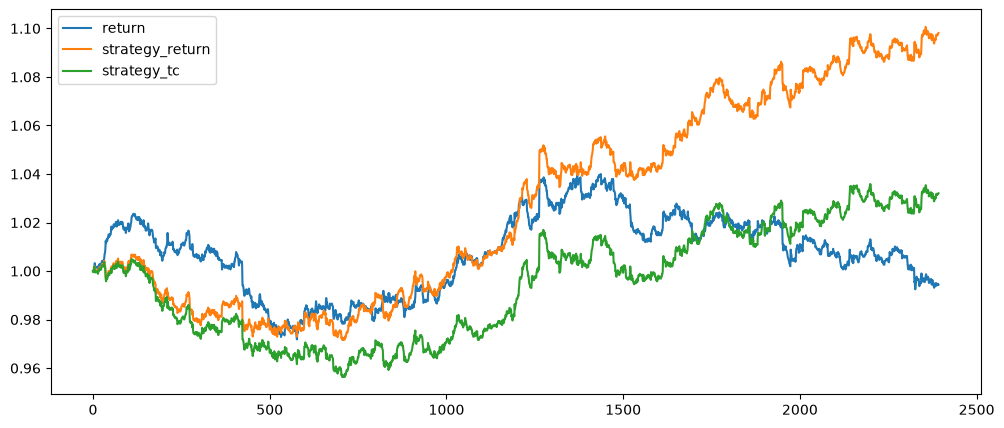

In [16]:
# 横轴用 K 线序号，避免休市空档被画成斜线
test[['return', 'strategy_return', 'strategy_tc']].cumsum().apply(np.exp).reset_index(drop=True).plot(figsize=(12, 5));

本次结果基于 8,000 根原始 K 线（2025-11-10 21:00:00 至 2026-10-26 14:40:00）。构造特征后剩余 7,974 个样本，按时间划分为 5,581 个训练样本和 2,393 个测试样本；测试期为 2026-07-13 14:30:00 至 2026-10-26 14:40:00。

- `return`：累计增长倍数 **0.994435**，即收益 **-0.56%**，代表始终保持 1 倍多头敞口的被动基准。
- `strategy_return`：累计增长倍数 **1.098107**，即扣费前收益 **9.81%**。
- `strategy_tc`：累计增长倍数 **1.032092**，即扣费后收益 **3.21%**。按当前规则计费 **620 次**，包括首次建仓和 619 次方向切换，成本使累计收益降低约 **6.60 个百分点**。

测试集方向命中率为 **58.42%**。本例扣费后仍跑赢多头基准，但频繁换向消耗了大量毛收益：平均约每 3.9 根 K 线发生一次计费事件。收益不仅取决于判对次数，还取决于判对与判错时的波动幅度，以及交易成本。

向量化回测便于快速比较收益，但当前实现没有逐笔维护合约手数、资金及订单状态。固定金额手续费可以结合交易数量另行计算；仅用平均比例成本折算通常不够精确。如果要细化开平仓费用、成交时点与保证金约束，应进一步使用事件驱动回测，逐根 K 线处理交易事件。

到这里回答的是“不加杠杆时，这个预测信号表现如何”。接下来保持信号不变，考察仓位大小对资金曲线的影响。


## 2. 最优杠杆

Kelly 准则此前已经学过，这里只回顾计算方式：若单期简单收益的均值为 $m$、方差为 $s^2$，在无风险利率与融资利率均为 0 的连续近似下，平均对数增长率近似为

$$
g(f)\approx fm-\frac12f^2s^2,
\qquad f^*\approx\frac{m}{s^2}.
$$

对上述二次式求导即可得到满 Kelly；半 Kelly 则取其一半。本节重点是如何将这个估计用于当前收益序列，以及如何解读杠杆曲线。


### 2.1. 收益转换与年化统计

简单收益表示当期盈亏占期初资金的比例，对数收益则是资金增长倍数的自然对数：

$$
r_t=\ln(1+R_t),\qquad R_t=e^{r_t}-1.
$$

固定杠杆放大的是头寸规模，因此也直接放大当期盈亏比例：简单收益为 $R_t$ 时，$L$ 倍杠杆后的简单收益为 $LR_t$。代码先用 `np.expm1()`（即 $e^r-1$）将测试期对数收益转换为简单收益，再估计 $m$ 和 $s^2$。

本例假设闲置资金不生息、借款不付利息。不考虑借贷利差时，带无风险利率的近似式为 $f^*\approx(m-r_f)/s^2$；这里取 $r_f=0$，得到 $m/s^2$。该公式对对数增长率作二阶近似，忽略更高阶项，并用方差近似收益的二阶矩，因此不一定恰好对应本段样本收益最高的杠杆。

下面的 `.mean()` 和 `.var()` 首先得到每根 10 分钟 K 线的统计量。代码按实际数据跨度计算 `ann_factor`，再将均值和方差乘以该因子，波动率取年化方差的平方根。在收益可按这一假设缩放时，均值与方差同乘一个因子，不改变两者比值，因此不改变 Kelly 杠杆。这里的年化均值是统计量缩放，并非实际持有一年的复合收益率。

确定杠杆后，用 `np.log1p(L * R)`（即 $\ln(1+LR)$）转回对数收益。对数收益可以直接累加，最后取指数还原资金增长倍数。转回对数收益是为了便于累加。


In [17]:
span_days = (data.index[-1] - data.index[0]) / pd.Timedelta(days=1)
ann_factor = len(data) * 365 / span_days  
print("span_days=", span_days, "ann_factor=",ann_factor)

span_days= 349.0486111111111 ann_factor= 8338.408769870483


In [18]:
simple_returns = np.expm1(test[['return', 'strategy_tc']]) # np.expm1(x) = exp(x) - 1

# `.mean()` 和 `.var()` 得到的是每根 10 分钟 K 线的均值和方差。
mean = simple_returns.mean() * ann_factor
var = simple_returns.var() * ann_factor
vol = var ** 0.5
f_star = mean / var
f_star_half = 0.5 * mean / var

kelly_table = pd.DataFrame(
    {
        'mean': mean,
        'var': var,
        'vol': vol,
        'f_star': f_star,
        'f_star_half': f_star_half,
    }
).T.rename(columns={'return': 'buy_hold', 'strategy_tc': 'strategy_tc'})
print(kelly_table.to_string(float_format=lambda x: f'{x: .4f}'))

             buy_hold  strategy_tc
mean          -0.0143       0.1152
var            0.0103       0.0103
vol            0.1014       0.1015
f_star        -1.3919      11.1930
f_star_half   -0.6959       5.5965


本次 buy&hold 的年化简单收益均值为 -0.0143、方差为 0.010280、波动率为 10.14%；扣费后策略分别为 0.1152、0.010293 和 10.15%。这里的年化均值不是一年复合收益率。

buy&hold 的满 Kelly 估计为 -1.39 倍，半 Kelly 为 -0.70 倍；策略的满 Kelly 为 **11.19 倍**，半 Kelly 为 **5.60 倍**。 不过这些都是同一测试期上的事后估计。

两者的波动率较为接近，与策略始终保持绝对值为 1 的仓位有关：扣费前，两者每期对数收益的平方相同。但方差还取决于收益均值，且此处统计的是简单收益。因此，在单期收益和成本较小时，两者的波动率通常接近，但不必相等。

正 Kelly 值表示沿原收益序列的方向配置敞口，负值表示反向配置。例如，被动多头基准的 Kelly 值为负，意味着转为做空。下面的策略图只处理满 Kelly 为正的情况。

### 2.2. 比较不同杠杆的资金曲线

图中比较策略 1 倍、四分之一 Kelly、半 Kelly、满 Kelly 和 1.5 倍 Kelly，另以灰色虚线标出被动多头基准。策略颜色随实际杠杆增大由浅蓝加深，具体倍数自动显示在图例中。


In [19]:
# 不计融资成本、保证金追缴、滑点及合约手数取整。
strategy_simple = simple_returns['strategy_tc']
full_kelly = float(f_star['strategy_tc'])
if not np.isfinite(full_kelly) or full_kelly <= 0:
    raise ValueError('当前 Kelly 估计不是正的有限值，不能沿用本例的正杠杆比较。')

levels = {
    'Strategy 1x': 1.0,
    '0.25 Kelly': 0.25 * full_kelly,
    '0.5 Kelly': 0.5 * full_kelly,
    '1.0 Kelly': full_kelly,
    '1.5 Kelly': 1.5 * full_kelly,
}


def fixed_leverage_log_returns(strategy_simple, leverage):
    growth = 1 + leverage * strategy_simple
    if not np.isfinite(growth).all() or (growth <= 0).any():
        raise ValueError(
            f'{leverage:.2f} 倍杠杆出现非有限收益或权益耗尽，需单独处理破产情形。'
        )
    return np.log(growth)


# 计算各杠杆下的资金增长倍数，列按杠杆从小到大排列。
leveraged_returns = pd.DataFrame(index=test.index)  # 保留各杠杆的对数收益，供风险分析复用
wealth = pd.DataFrame(index=test.index)
wealth['Buy & hold 1x'] = (1 + simple_returns['return']).cumprod()
ordered_levels = sorted(levels.items(), key=lambda item: item[1])
for label, leverage in ordered_levels:
    name = f'{label} ({leverage:.2f}x)'
    leveraged_returns[label] = fixed_leverage_log_returns(strategy_simple, leverage)
    wealth[name] = np.exp(leveraged_returns[label].cumsum())


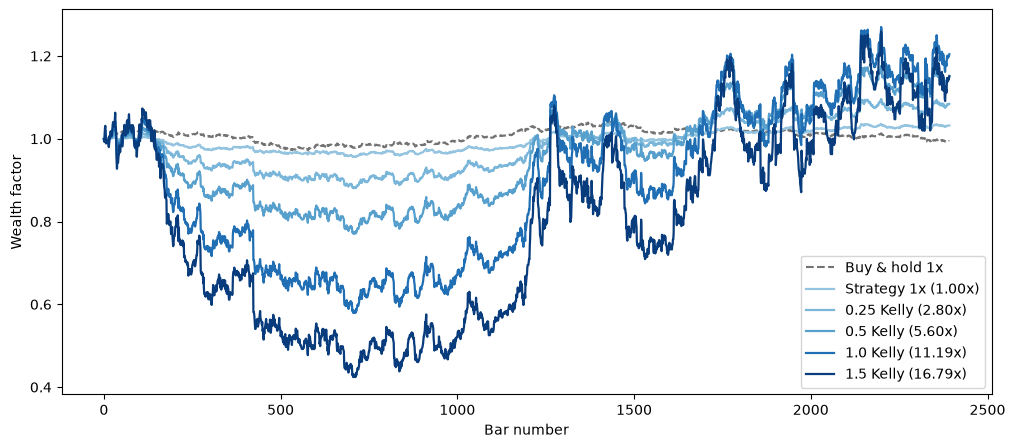

In [20]:
# 绘图：基准用灰色虚线，策略随杠杆增大由浅蓝变为深蓝。
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(wealth.iloc[:, 0].to_numpy(), '--', color='0.45', label=wealth.columns[0])

low, high = min(levels.values()), max(levels.values())
for column, (_, leverage) in zip(wealth.columns[1:], ordered_levels):
    shade = 0.4 + 0.55 * (leverage - low) / (high - low)
    ax.plot(wealth[column].to_numpy(), color=plt.get_cmap('Blues')(shade),
            linewidth=1.6, label=column)

ax.set(xlabel='Bar number', ylabel='Wealth factor')
ax.legend()
plt.show()


In [21]:
wealth.iloc[-1]  # 查看六条资金曲线各自最后的资金增长倍数


Buy & hold 1x          0.994435
Strategy 1x (1.00x)    1.032092
0.25 Kelly (2.80x)     1.084343
0.5 Kelly (5.60x)      1.149021
1.0 Kelly (11.19x)     1.204320
1.5 Kelly (16.79x)     1.151782
Name: 2026-10-26 14:40:00, dtype: float64

1. 读图时，先比较最终资金增长倍数，再比较途中资金下降的幅度。杠杆更大，最终赚到的钱不一定更多，过程中承受的损失也可能明显增加。

2. 本图在每根 K 线结束时根据账户净值调整仓位，使杠杆倍数保持不变。如果某一期亏损达到或超过账户全部资金，代码会停止并提示。

3. 这里对转换后的策略收益按固定杠杆计算复利，基础策略的收益和费用仍沿用前面的近似。图中未模拟融资成本、保证金追缴、滑点和合约手数取整，不能据此判断某个杠杆在期货账户中是否实际可用。

4. 要区分预测模型与仓位管理的测试范围：测试集没有参与 AdaBoost 训练，因此模型预测属于样本外结果；但 Kelly 杠杆又是用测试期收益估计后应用于同一时期的，相当于看过这段行情的盈亏后再确定杠杆。因此，这张图属于事后分析，不能作为完整策略的独立样本外检验。严格测试时，应在训练期或独立校准期确定杠杆，再应用到测试期。

5. 本例样本较短，年化收益与 Kelly 估计易受少数交易影响，仅用于方法演示,不构成收益承诺。

## 3. 风险分析

-- 接下来固定使用半 Kelly，进一步分析资金曲线的风险。

收益曲线告诉我们最终赚了多少，风险分析则继续回答两个问题：途中最多损失了多少、多久才能恢复，以及单个持有期可能出现多大的损失。

本节使用前文估计的半 Kelly 杠杆 `risk_leverage`，初始账户资金设为 100,000 元。每根 K 线按当时账户净值维持固定杠杆，头寸规模随净值变化。这个金额用于统一展示人民币损益，未模拟合约手数和保证金约束。

### 3.1. 最大回撤与回撤持续时间

更多关于 **回撤** 的知识请复习 **《量化交易：如何建立自己的算法交易事业》学习笔记** 的 3.3 **绩效衡量指标**。

回撤金额是此前最高净值减去当前净值；除以此前最高净值，得到回撤比例。本图用最大回撤比例表示回撤深度，同时保留回撤金额的计算。回撤持续时间关注的是账户跌离此前高点后，需要多久才能回到该高点。

下面先复用已计算的半 Kelly 收益，生成账户净值曲线，并在曲线开头补上初始资金点。历史最高净值只计算一次，再由它得到回撤金额与回撤比例。两种最大值可能发生在不同时间；图中红线标记最大回撤比例。

In [ ]:
# 1. 复用半 Kelly 收益，计算账户净值。
equity = 100_000  # 初始资金，人民币元
risk_leverage = levels['0.5 Kelly']
risk = pd.DataFrame({'log_return': leveraged_returns['0.5 Kelly']})
# CSV 标记 K 线起点；该根收益在结束时才实现，风险分析改用结束时间。
bar_end = data.index + pd.Timedelta(seconds=bar_seconds)
# 螺纹钢上午 10:15 休市：10:10 开始的这根 K 线仅持续 5 分钟。
bar_end = bar_end.where(bar_end.strftime('%H:%M') != '10:20',
                        bar_end.normalize() + pd.Timedelta(hours=10, minutes=15))
risk.index = bar_end[split:]
risk['equity'] = np.exp(risk['log_return'].cumsum()) * equity  # 账户净值

# 2. 补上初始资金点，统一计算历史高点与回撤。
initial_time = bar_end[split - 1]  # 首笔收益的起点：测试期前一根 K 线的结束时间
equity_curve = pd.concat([pd.Series([equity], index=[initial_time]), risk['equity']])

high_watermark = equity_curve.cummax()  # 包含初始资金
drawdown_amount = high_watermark - equity_curve
drawdown_pct = drawdown_amount / high_watermark
risk['cummax'] = high_watermark     # 按 risk 的时间索引重新对齐数据
risk['drawdown'] = drawdown_amount  # 按 risk 的时间索引重新对齐数据

max_dd = drawdown_pct.max()
t_max = drawdown_pct.idxmax()
print(f"半 Kelly：{risk_leverage:.2f} 倍，最大回撤金额：{drawdown_amount.max():,.2f} 元; 最大回撤比例：{max_dd:.2%}，发生于 {t_max}")


In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(12, 5), sharex=True)

# 上图：账户净值与截至当时的历史最高净值。
axes[0].plot(equity_curve.index, equity_curve, color='#1f77b4', linewidth=1, label='Account equity')
axes[0].plot(high_watermark.index, high_watermark, '--', color='#ff7f0e', linewidth=1, label='High-water mark')
axes[0].set(title='Account Equity vs. High-Water Mark', ylabel='Account equity (CNY)')

# 下图：回撤取负值，表示相对历史高点下跌的比例。
axes[1].fill_between(drawdown_pct.index, 0, -drawdown_pct, color='red', alpha=0.3, label='Drawdown')
axes[1].set(title='Drawdown Analysis', xlabel='Time', ylabel='Drawdown from peak')
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f'{value:.0%}'))

for ax in axes:
    ax.legend()
    ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()


接着计算每个时点距离最近高点的时长，取其中最长的一段。恢复高点的时刻也计入持续时间；若期末尚未恢复，则统计截至期末的已持续时间。连续创新高不算回撤。


In [ ]:
# 计算每个时点距最近高点的时长。
times = pd.Series(drawdown_pct.index, index=drawdown_pct.index)
peak_times = times.where(drawdown_pct == 0).ffill()
durations = times - peak_times

# 恢复高点的那根 K 线，也计入回撤持续时间。
just_recovered = (drawdown_pct == 0) & (drawdown_pct.shift() > 0) # 找到高点中刚刚恢复的高点
durations.loc[just_recovered] = (times - peak_times.shift()).loc[just_recovered] # 还原刚恢复的高点的实际 recover 的时间

# 最长回撤持续区间及其恢复状态。
dd_end = durations.idxmax()
t_per = durations.loc[dd_end]
dd_start = dd_end - t_per
recovered = drawdown_pct.loc[dd_end] == 0.

# 最大回撤比例所在区间的恢复状态。
max_dd_recovered = (equity_curve.loc[t_max:] >= high_watermark.loc[t_max]).any()

print(f"最大回撤比例：{max_dd:.2%}"
      f"（{'已恢复' if max_dd_recovered else '截至期末仍未恢复'}）")
print(f"最大回撤金额：{drawdown_amount.max():,.2f} 元")
print(f"最长回撤持续时间：{t_per}，约 {t_per.total_seconds() / 3600:.2f} 小时"
      f"（{'已恢复' if recovered else '截至期末仍未恢复'}）")

In [ ]:
cum_return = equity_curve / equity - 1
peak_return = high_watermark / equity - 1

图中蓝线为相对初始资金的累计收益率，灰色区域为它与历史高点之间的差距。红色竖线表示最大回撤深度，图例显示相对当时高点的跌幅；绿色横线表示最长回撤持续区间。最深的回撤与恢复最慢的回撤，不一定是同一段。

持续时间使用日历时间，包含休市时段。若最长区间到样本末尾仍未恢复，图例会注明“ongoing”，其持续时间只是截至期末的已观察时长。


In [ ]:
fig, ax = plt.subplots(figsize=(12, 3))
# 画蓝线
ax.plot(cum_return.index, cum_return, '-o', linewidth=0.6, markersize=1, color='#1f77b4', label='Cumulative return')
# 画灰色区域
ax.fill_between(cum_return.index, cum_return, peak_return, color='gray', alpha=0.2)
# 画红线
ax.vlines(t_max, cum_return.loc[t_max], peak_return.loc[t_max], color='red', linewidth=0.6, label=f'Max drawdown ({max_dd:.2%})')
# 画绿线
if t_per > pd.Timedelta(0):
    duration_days = t_per.total_seconds() / 86400
    status = '' if recovered else ', ongoing'
    ax.hlines(cum_return.loc[dd_start], dd_start, dd_end, color='green', linewidth=0.6,
              label=f'Max DD duration ({duration_days:.2f} days{status})')
# 画 recovery point
recovery_points = cum_return.loc[just_recovered]
ax.scatter(recovery_points.index, recovery_points, color='darkorange', linewidths=0.6, s=5, zorder=5, label='Recovery Point')

ax.set(title='Max Drawdown Depth vs. Max Drawdown Duration', xlabel='Time', ylabel='Cumulative return')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f'{value:.0%}'))
ax.legend()
fig.tight_layout()
plt.show()

### 3.2. 风险价值（VaR）

更多关于 VaR 的知识请复习 **《量化必备：概率论与统计学基础》** 中的 **2.13 VaR (value at Risk)**。 

回撤描述整条资金路径上的损失，VaR 则关注指定持有期内的损失分位数。例如，10 分钟、95% 置信水平的 VaR 为 1,000 元，表示按估计分布，约有 5% 的 10 分钟持有期会损失超过 1,000 元；它不是最大可能损失。

本例用半 Kelly 策略的历史收益计算经验分位数。先把 `risk['log_return']` 转为简单收益，再乘以初始资金 100,000 元，得到统一本金下的损益。因此，表中的 VaR 是按固定本金折算的人民币金额，不是沿动态净值曲线逐期记录的实际损益。

In [ ]:
import scipy.stats as scs
from IPython.display import display

percs = [0.01, 0.1, 1., 2.5, 5.0, 10.0]  # 损益分布的左尾百分位：5 对应 95% 置信水平，1 对应 99%
risk['return'] = np.expm1(risk['log_return'])
VaR = scs.scoreatpercentile(equity * risk['return'], percs)  # 提取左尾损益分位数，通常为负值


def print_var():
    table = pd.DataFrame({
        '左尾概率 p（%）': percs,
        '置信水平': [100 - p for p in percs],
        'VaR': -VaR,  # 损益分位数取反，以损失金额显示；alpha = 1 - p / 100
        '解释': [
            f'按历史样本估计，{100 - p:g}% 的概率损失不超过 {loss:,.2f} 元'
            for p, loss in zip(percs, -VaR)
        ],
        '实际用途': [
            '观察极端尾部；短样本估计很不稳定',
            '观察极端尾部；需更长样本验证',
            '观察较低频的大额损失阈值',
            '观察较高置信水平下的损失阈值',
            '观察较常见的尾部损失阈值',
            '观察更频繁的不利波动',
        ],
    })
    display(table.style.format({
        '左尾概率 p（%）': '{:.2f}',
        '置信水平': '{:.2f}%',
        'VaR': '{:,.2f}',
    }).hide(axis='index'))


print_var()


下面按 K 线结束时间汇总对数收益，再转换为简单收益，计算小时分组 VaR。分组采用左开右闭区间，例如 (09:00, 10:00] 包含 10:00 结束的 K 线。部分分组不足 6 根，无数据的小时不参与计算；跨休市的收盘到收盘收益还包含休市期间的价格变化，因此这不是严格固定一小时持有期的 VaR。

In [ ]:
# 按小时汇总对数收益，再还原简单收益；无交易数据的小时不参与估计。
hourly_log_return = risk['log_return'].resample('1h', closed='right', label='right').sum(min_count=1)
hourly_return = np.expm1(hourly_log_return.dropna())
VaR = scs.scoreatpercentile(equity * hourly_return, percs)

print_var()


在各期收益独立、分布稳定且均值可忽略等假设下，VaR 常用平方根时间法近似, 表中数据也比较符合这个倍数。VaR 的可靠性取决于样本是否足以代表未来风险。当前数据较短，99.9%、99.99% 等极端分位数主要由少数最差样本及插值决定，不能视为可靠的极端损失预测。VaR 也不说明超过阈值后还会损失多少，应结合前面的回撤与净值曲线理解。


## 4. 保存模型对象

完成回测、杠杆与风险分析后，可以保存模型和预处理参数，供后续复现与加载使用。保存对象本身并不代表策略已经具备实盘部署条件。

`algorithm` 中的 `model` 保存训练好的 AdaBoost 分类器，`mu` 和 `std` 保存训练集标准化参数。以后对新数据预测时，仍须按照相同的特征定义、滞后阶数与列顺序生成输入，并使用这里保存的均值和标准差，不能重新用预测数据估计它们。


同时保存训练时的标的、K 线周期、滚动窗口、滞后阶数、基础特征及输入列顺序。在线预测和离线核对均从这份训练配置读取参数，避免重复手写配置导致偏差；另保存原测试期起点，便于选取相同的验证时段。

In [29]:
import pickle

algorithm = {
    'model': model,
    'mu': mu,
    'std': std,
    'instrument': instrument,
    'bar_seconds': bar_seconds,
    'window': window,
    'momentum_tol': momentum_tol,
    'lags': lags,
    'features': features.copy(),
    'cols': cols.copy(),
    'test_start': data.index[split],  # 记录原测试期起点，供在线一致性核对
}

with open('algorithm.pkl', 'wb') as f:
    pickle.dump(algorithm, f)

运行后会在当前工作目录生成 `algorithm.pkl`。它保存模型、标准化参数和训练配置，不包含行情数据、特征构造代码、Kelly 杠杆或订单执行逻辑；复现完整策略仍需保留本 Notebook 及相应环境。
